In [2]:
# Definición de diccionario con tus lugares en San Jerónimo, Cusco (latitud, longitud)
lugares = {
    "Casa (Calle Romeritos 820)":      (-13.5429, -71.8811),
    "Colegio Fe y Alegria Nro 21":            (-13.54433, -71.88143),
    "Plaza de Armas de San Jeronimo":  (-13.54397, -71.88422),
    "Mercado Vinocanchon":             (-13.54359, -71.88781),
}

for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

Casa (Calle Romeritos 820): lat=-13.5429, lon=-71.8811
Colegio Fe y Alegria Nro 21: lat=-13.54433, lon=-71.88143
Plaza de Armas de San Jeronimo: lat=-13.54397, lon=-71.88422
Mercado Vinocanchon: lat=-13.54359, lon=-71.88781


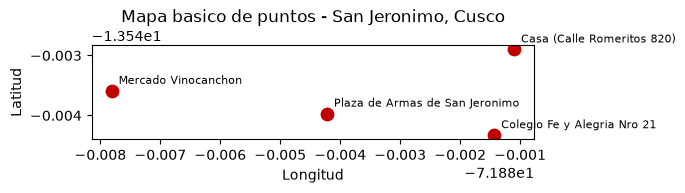

In [4]:
import matplotlib.pyplot as plt

# Extraer latitudes (eje Y), longitudes (eje X) y nombres
lats = [v[0] for v in lugares.values()]
lons = [v[1] for v in lugares.values()]
nombres = list(lugares.keys())

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(lons, lats, c="#C00000", s=80)

for nombre, lon, lat in zip(nombres, lons, lats):
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Mapa basico de puntos - San Jeronimo, Cusco")
ax.set_aspect("equal")  # Evita distorsión visual de las proporciones en pantalla
plt.tight_layout()
plt.savefig("mapa_basico.png")
plt.show()

In [6]:
# TAREA 2
import math

# Completa: define la funcion distancia_haversine
def distancia_haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # Radio promedio de la Tierra en km
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return R * c

In [7]:
# Completa: calcula las distancias desde tu primer lugar
primer_lugar = "Casa (Calle Romeritos 820)"
lat0, lon0 = lugares[primer_lugar]

for nombre, (lat, lon) in lugares.items():
    if nombre == primer_lugar:
        continue
    d = distancia_haversine(lat0, lon0, lat, lon)
    print(f"{primer_lugar} -> {nombre}: {d:.4f} km")

Casa (Calle Romeritos 820) -> Colegio Fe y Alegria Nro 21: 0.1630 km
Casa (Calle Romeritos 820) -> Plaza de Armas de San Jeronimo: 0.3577 km
Casa (Calle Romeritos 820) -> Mercado Vinocanchon: 0.7294 km


In [8]:
# Completa: identifica el par mas cercano y el mas lejano
from itertools import combinations

distancias_pares = []
for (n1, (lat1, lon1)), (n2, (lat2, lon2)) in combinations(lugares.items(), 2):
    d = distancia_haversine(lat1, lon1, lat2, lon2)
    distancias_pares.append((d, n1, n2))

mas_cercano = min(distancias_pares)
mas_lejano = max(distancias_pares)

print(f"Par mas cercano: {mas_cercano[1]} y {mas_cercano[2]} ({mas_cercano[0]:.4f} km)")
print(f"Par mas lejano:  {mas_lejano[1]} y {mas_lejano[2]} ({mas_lejano[0]:.4f} km)")

Par mas cercano: Casa (Calle Romeritos 820) y Colegio Fe y Alegria Nro 21 (0.1630 km)
Par mas lejano:  Casa (Calle Romeritos 820) y Mercado Vinocanchon (0.7294 km)


In [9]:
#TAREA 3
import json

# Completa: construye la lista de features y el GeoJSON completo
features = []
for nombre, (lat, lon) in lugares.items():
    features.append({
        "type": "Feature",
        "properties": {"nombre": nombre},
        "geometry": {
            "type": "Point",
            "coordinates": [lon, lat]  # Orden estándar GeoJSON: [longitud, latitud]
        }
    })

geojson_mio = {"type": "FeatureCollection", "features": features}

# Completa: guarda el archivo
with open("mis_lugares.geojson", "w", encoding="utf-8") as f:
    json.dump(geojson_mio, f, indent=2)

print("Archivo guardado con", len(features), "features")

Archivo guardado con 4 features


In [10]:
# Completa: reabre y verifica
with open("mis_lugares.geojson", encoding="utf-8") as f:
    data = json.load(f)

print("Cantidad de features:", len(data["features"]))
print("Primer lugar:", data["features"][0]["properties"]["nombre"])
print("Sus coordenadas [lon, lat]:", data["features"][0]["geometry"]["coordinates"])

Cantidad de features: 4
Primer lugar: Casa (Calle Romeritos 820)
Sus coordenadas [lon, lat]: [-71.8811, -13.5429]
